In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

IMG_DIR = Path("data")

# 1. Wczytanie zbioru

In [2]:
def load_mask(path):
    gray = np.array(Image.open(path).convert("L"))
    return gray > 127

paths = sorted(
    p for p in IMG_DIR.rglob("*.gif")
    if p.stem.rsplit("-", 1)[-1].isdigit()   # tylko pliki ".gif"
)
masks = [load_mask(p) for p in paths]
labels = np.array([p.stem.rsplit("-", 1)[0].lower() for p in paths])

In [3]:
counts = Counter(labels)
heights = [m.shape[0] for m in masks]
widths = [m.shape[1] for m in masks]

print("Obrazów:", len(masks))
print("Klas:", len(counts))
print("Obrazów na klasę: od", min(counts.values()), "do", max(counts.values()))
print("Wysokość: od", min(heights), "do", max(heights), "px")
print("Szerokość: od", min(widths), "do", max(widths), "px")

Obrazów: 1400
Klas: 70
Obrazów na klasę: od 20 do 20
Wysokość: od 38 do 986 px
Szerokość: od 50 do 1116 px


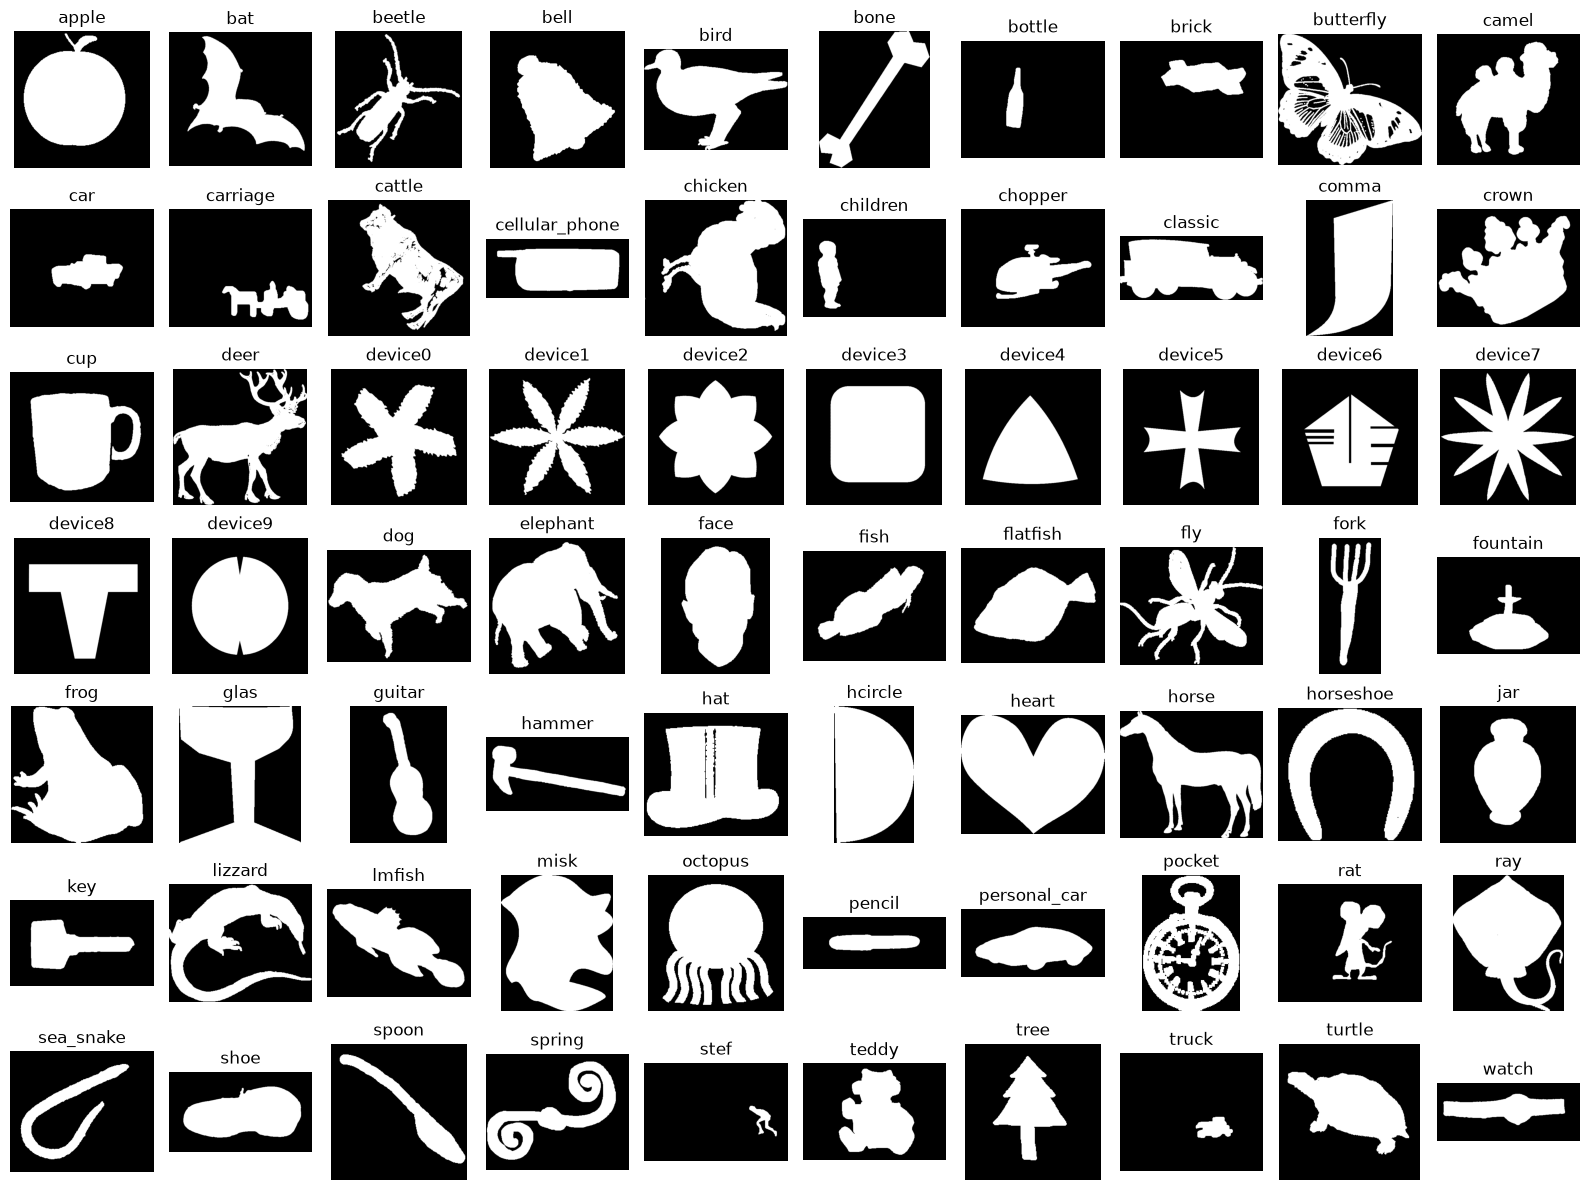

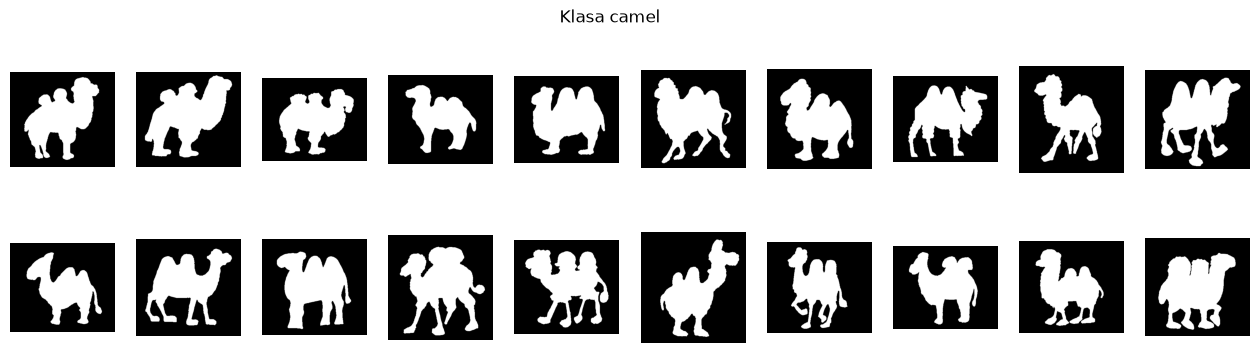

In [4]:
classes = np.unique(labels)

fig, axes = plt.subplots(7, 10, figsize=(16, 12))
for ax, c in zip(axes.flat, classes):
    i = np.flatnonzero(labels == c)[0]
    ax.imshow(masks[i], cmap="gray")
    ax.set_title(c)
    ax.axis("off")
plt.tight_layout()
plt.show()

idx_camel = np.flatnonzero(labels == "camel")
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
for ax, i in zip(axes.flat, idx_camel[:20]):
    ax.imshow(masks[i], cmap="gray")
    ax.axis("off")
plt.suptitle("Klasa camel")
plt.show()

# 2. Podział na train, val i test

In [5]:
idx_all = np.arange(len(labels))

idx_train, idx_rest = train_test_split(idx_all, test_size=0.4, stratify=labels, random_state=42)

idx_val, idx_test = train_test_split(idx_rest, test_size=0.5, stratify=labels[idx_rest], random_state=42)

y_train, y_val, y_test = labels[idx_train], labels[idx_val], labels[idx_test]

print("Rozmiary:", len(idx_train), len(idx_val), len(idx_test))
for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    c = Counter(y)
    print(f"{name}: od {min(c.values())} do {max(c.values())} obrazów na klasę")

Rozmiary: 840 280 280
train: od 12 do 12 obrazów na klasę
val: od 4 do 4 obrazów na klasę
test: od 4 do 4 obrazów na klasę


# 3. Cechy proste

Masek z więcej niż jedną składową: 72
Counter({'butterfly': 10, 'pocket': 10, 'device7': 7, 'dog': 6, 'cattle': 4, 'horseshoe': 4, 'turtle': 4, 'bat': 3, 'chicken': 3, 'device1': 3, 'horse': 3, 'frog': 2, 'guitar': 2, 'stef': 2, 'chopper': 1, 'crown': 1, 'device0': 1, 'device4': 1, 'device9': 1, 'elephant': 1, 'fly': 1, 'lizzard': 1, 'shoe': 1})


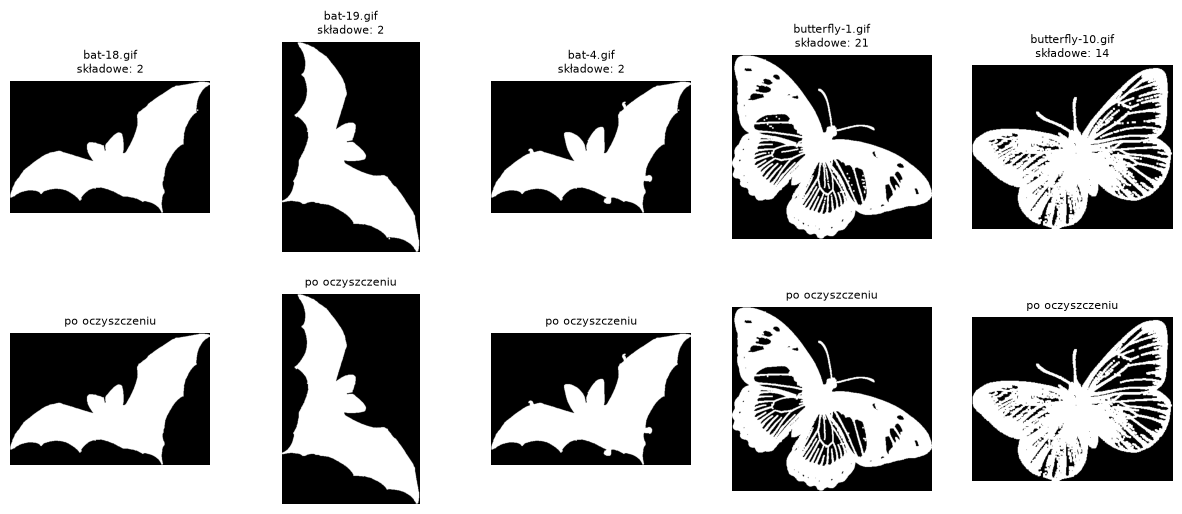

In [6]:
from skimage.measure import label, regionprops

def largest_component(mask):
    lab = label(mask, connectivity=2)
    if lab.max() <= 1:
        return mask
    sizes = np.bincount(lab.ravel())
    sizes[0] = 0
    return lab == sizes.argmax()

n_comp = np.array([label(m, connectivity=2).max() for m in masks])
print("Masek z więcej niż jedną składową:", (n_comp > 1).sum())
print(Counter(labels[n_comp > 1].tolist()))

show = np.flatnonzero(n_comp > 1)[:5]
before = [masks[i] for i in show]           # oryginały do podglądu
masks = [largest_component(m) for m in masks]

if len(show) > 0:
    fig, axes = plt.subplots(2, len(show), figsize=(3 * len(show), 6), squeeze=False)
    for j, i in enumerate(show):
        axes[0, j].imshow(before[j], cmap="gray")
        axes[0, j].set_title(f"{paths[i].name}\nskładowe: {n_comp[i]}", fontsize=8)
        axes[1, j].imshow(masks[i], cmap="gray")
        axes[1, j].set_title("po oczyszczeniu", fontsize=8)
    for ax in axes.flat:
        ax.axis("off")
    plt.show()

In [7]:
import pandas as pd

SIMPLE_NAMES = ["area", "perimeter", "feret_diameter", "bbox_width", "bbox_height"]

def simple_features(mask):
    r = regionprops(mask.astype(np.uint8))[0]
    min_row, min_col, max_row, max_col = r.bbox
    return [
        r.area,                  # S: liczba pikseli obiektu
        r.perimeter,             # L: długość brzegu
        r.feret_diameter_max,    # D: największa odległość między punktami obiektu
        max_col - min_col,       # W: szerokość prostokąta otaczającego
        max_row - min_row,       # H: wysokość prostokąta otaczającego
    ]


X_simple = np.array([simple_features(m) for m in masks])
df_simple = pd.DataFrame(X_simple, columns=SIMPLE_NAMES)
print(X_simple.shape)
df_simple.describe().round(1)

(1400, 5)


,area,perimeter,feret_diameter,bbox_width,bbox_height
count,1400.0,1400.0,1400.0,1400.0,1400.0
mean,45196.1,1649.3,354.1,300.9,268.0
std,40869.8,1333.8,156.8,149.6,142.5
min,1139.0,155.9,50.6,40.0,31.0
25%,13689.5,823.1,230.0,191.0,154.0
50%,31871.0,1258.3,339.4,287.0,248.5
75%,66037.2,2006.6,450.4,396.0,380.0
max,346056.0,11457.0,1108.2,1108.0,802.0


In [8]:
from skimage.transform import rescale, rotate

m = masks[idx_camel[0]]
variants = {
    "original": m,
    "skala x2": rescale(m, 2, order=0),
    "obrót 45": rotate(m, 45, order=0, resize=True)
}

pd.DataFrame(
    {name: simple_features(v > 0) for name, v in variants.items()},
    index=SIMPLE_NAMES
).round(1)

,original,skala x2,obrót 45
area,44137.0,176548.0,44160.0
perimeter,1581.1,3469.1,1664.2
feret_diameter,353.9,708.2,354.8
bbox_width,279.0,558.0,247.0
bbox_height,308.0,616.0,353.0


# 4. Cechy złożone

In [9]:
from scipy import ndimage as ndi
from skimage.measure import find_contours

COMPLEX_NAMES = [
    "compactness", "solidity", "aspect_ratio", "ellipticity",
    "r_min_max", "circ_variance", "asym_best", "asym_worst"
]

def outer_contour(mask):
    """Punkty zewnętrznego brzegu (wiersz, kolumna), bez brzegów dziur."""
    filled = ndi.binary_fill_holes(np.pad(mask, 1))      # ramka z tła, dziury zamalowane
    contour = max(find_contours(filled.astype(float), 0.5), key=len)
    return contour - 1                                    # cofamy przesunięcie od ramki


def asymmetry(mask, r):
    rows, cols = np.nonzero(mask)
    r0, c0 = np.rint(r.centroid).astype(int)
    R = int(np.ceil(np.hypot(rows - r0, cols - c0).max())) + 1
    canvas = np.zeros((2 * R + 1, 2 * R + 1), dtype=bool)
    canvas[rows - r0 + R, cols - c0 + R] = True
    angle = -np.degrees(r.orientation)
    aligned = ndi.rotate(canvas, angle, reshape=False, order=0)
    scores = []
    for mirrored in (np.fliplr(aligned), np.flipud(aligned)):
        overlap = (aligned & mirrored).sum() / (aligned | mirrored).sum()
        scores.append(1 - overlap)
    return min(scores), max(scores)


def complex_features(mask):
    r = regionprops(mask.astype(np.uint8))[0]
    S, L = r.area, r.perimeter
    
    c = outer_contour(mask)
    d = np.hypot(c[:, 0] - r.centroid[0], c[:, 1] - r.centroid[1])
    
    mu = r.moments_central
    I1 = (mu[2, 0] * mu[0, 2] - mu[1, 1] ** 2) / mu[0, 0] ** 4
    e = 16 * np.pi ** 2 * I1
    
    asym_best, asym_worst = asymmetry(mask, r)
    return [
        4 * np.pi * S / L ** 2,                       # K: 1 dla koła
        r.solidity,                                   # pole / pole otoczki wypukłej
        r.axis_minor_length / r.axis_major_length,    # M1 / M2
        e if e <= 1 else 1 / e,                       # E_I: 1 dla elipsy
        d.min() / d.max(),                            # najkrótszy / najdłuższy promień
        d.std() / d.mean(),                           # wariancja cyrkulacji
        asym_best,                                    # asymetria względem lepszej osi
        asym_worst,                                   # asymetria względem gorszej osi
    ]

X_complex = np.array([complex_features(m) for m in masks])
df_complex = pd.DataFrame(X_complex, columns=COMPLEX_NAMES)
print(X_complex.shape)
df_complex.describe().round(3)

(1400, 8)


,compactness,solidity,aspect_ratio,ellipticity,r_min_max,circ_variance,asym_best,asym_worst
count,1400.000,1400.000,1400.000,1400.000,1400.000,1400.000,1400.000,1400.000
mean,0.293,0.719,0.590,0.628,0.268,0.319,0.291,0.442
std,0.191,0.173,0.252,0.252,0.167,0.108,0.188,0.208
min,0.004,0.201,0.058,0.025,0.001,0.006,0.000,0.005
25%,0.131,0.584,0.387,0.438,0.145,0.243,0.141,0.284
50%,0.255,0.757,0.571,0.692,0.257,0.316,0.266,0.411
75%,0.434,0.857,0.796,0.844,0.369,0.393,0.397,0.598
max,0.880,0.999,1.000,1.000,0.976,0.589,0.876,0.929


In [10]:
pd.DataFrame(
    {name: complex_features(v > 0) for name, v in variants.items()},
    index=COMPLEX_NAMES,
).round(3)

,original,skala x2,obrót 45
compactness,0.222,0.184,0.200
solidity,0.752,0.751,0.751
aspect_ratio,0.603,0.603,0.603
ellipticity,0.693,0.693,0.693
r_min_max,0.335,0.334,0.335
circ_variance,0.271,0.271,0.272
asym_best,0.405,0.407,0.406
asym_worst,0.430,0.430,0.431


## 5. Wybór cech i normalizacja

In [11]:
FEATURE_NAMES = SIMPLE_NAMES + COMPLEX_NAMES
df_all = pd.DataFrame(np.hstack([X_simple, X_complex]), columns=FEATURE_NAMES)
df_train = df_all.loc[idx_train]
print(df_all.shape, df_train.shape)

(1400, 13) (840, 13)


In [12]:
from sklearn.feature_selection import f_classif

F, _ = f_classif(df_train, y_train)
ranking = pd.Series(F, index=FEATURE_NAMES).sort_values(ascending=False)
print(ranking.round(1))

aspect_ratio      156.4
ellipticity        77.4
solidity           64.8
circ_variance      50.6
compactness        49.5
asym_worst         48.8
bbox_height        32.9
area               31.6
r_min_max          29.1
feret_diameter     27.0
bbox_width         26.7
asym_best          26.2
perimeter          20.2
dtype: float64


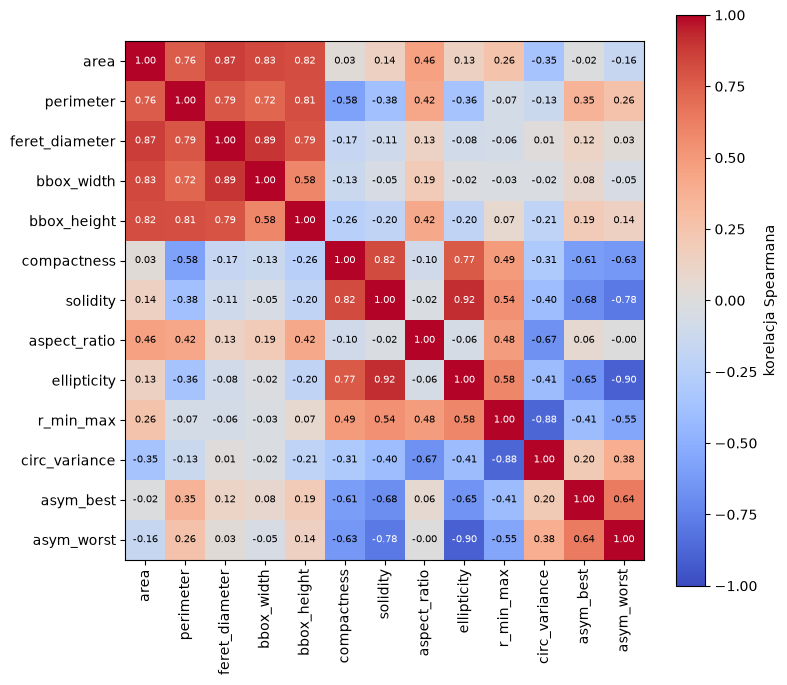

In [13]:
corr = df_train.corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=90)
ax.set_yticks(range(len(FEATURE_NAMES)), FEATURE_NAMES)
for i in range(len(FEATURE_NAMES)):
    for j in range(len(FEATURE_NAMES)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.7 else "black")
fig.colorbar(im, label="korelacja Spearmana")
plt.tight_layout()
plt.show()

In [14]:
THRESHOLD = 0.9

selected = []
for name in ranking.index:                       # od najsilniejszej cechy
    if all(abs(corr.loc[name, s]) < THRESHOLD for s in selected):
        selected.append(name)
print(len(selected), "cech:", selected)

11 cech: ['aspect_ratio', 'ellipticity', 'circ_variance', 'compactness', 'bbox_height', 'area', 'r_min_max', 'feret_diameter', 'bbox_width', 'asym_best', 'perimeter']


train: od 0.00 do 1.00
val: od -0.01 do 1.46
test: od -0.00 do 1.46


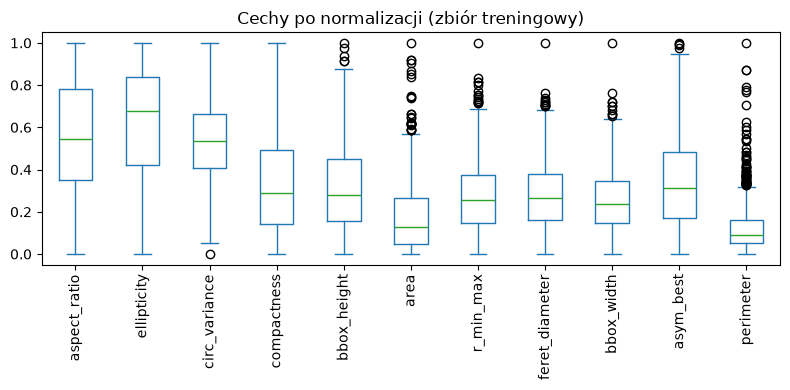

In [15]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(df_all.loc[idx_train, selected])
X_val = scaler.transform(df_all.loc[idx_val, selected])
X_test = scaler.transform(df_all.loc[idx_test, selected])

for name, X in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"{name}: od {X.min():.2f} do {X.max():.2f}")

pd.DataFrame(X_train, columns=selected).plot.box(rot=90, figsize=(8, 4))
plt.title("Cechy po normalizacji (zbiór treningowy)")
plt.tight_layout()
plt.show()

## 6. Klasyfikacja

In [16]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_val)

print(y_pred[:5], y_val[:5])
print("Accuracy (val):", round((y_pred == y_val).mean(), 3))

['chicken' 'fountain' 'device8' 'pocket' 'turtle'] ['chicken' 'fountain' 'device8' 'pocket' 'turtle']
Accuracy (val): 0.8


In [17]:
ks = [1, 3, 5, 7, 9, 11, 15]

val_acc = []
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    val_acc.append(knn.score(X_val, y_val))

print(pd.Series(val_acc, index=ks, name="val accuracy").round(3))

1     0.800
3     0.743
5     0.711
7     0.725
9     0.693
11    0.668
15    0.657
Name: val accuracy, dtype: float64


In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def val_accuracy(cols, scaler, k):
    """Uczy skaler i kNN na zbiorze treningowym, zwraca accuracy na walidacji."""
    model = make_pipeline(scaler(), KNeighborsClassifier(n_neighbors=k))
    model.fit(df_all.loc[idx_train, cols], y_train)
    return model.score(df_all.loc[idx_val, cols], y_val)


rows = []
for cols_name, cols in [("wybrane", selected), ("wszystkie 13", FEATURE_NAMES)]:
    for scaler in [MinMaxScaler, StandardScaler]:
        for k in ks:
            rows.append({
                "cechy": cols_name,
                "skaler": scaler.__name__,
                "k": k,
                "val_acc": val_accuracy(cols, scaler, k),
            })

results = pd.DataFrame(rows)
print(results.pivot_table(index="k", columns=["cechy", "skaler"], values="val_acc").round(3))

best = results.loc[results["val_acc"].idxmax()]
print("\nNajlepszy wariant:")
print(best)

cechy  wszystkie 13                     wybrane               
skaler MinMaxScaler StandardScaler MinMaxScaler StandardScaler
k                                                             
1             0.846          0.825        0.800          0.811
3             0.789          0.782        0.743          0.732
5             0.761          0.754        0.711          0.704
7             0.739          0.743        0.725          0.696
9             0.739          0.693        0.693          0.675
11            0.714          0.661        0.668          0.643
15            0.671          0.636        0.657          0.632

Najlepszy wariant:
cechy      wszystkie 13
skaler     MinMaxScaler
k                     1
val_acc        0.846429
Name: 14, dtype: object


In [19]:
BEST_COLS = FEATURE_NAMES       # albo selected
BEST_SCALER = MinMaxScaler      # albo StandardScaler
BEST_K = 1

## 7. Accuracy, precision, recall i macierz pomyłek

In [20]:
from sklearn.metrics import accuracy_score

final_model = make_pipeline(BEST_SCALER(), KNeighborsClassifier(n_neighbors=BEST_K))
final_model.fit(df_all.loc[idx_train, BEST_COLS], y_train)
y_pred = final_model.predict(df_all.loc[idx_test, BEST_COLS])

print("Accuracy (val): ", round(final_model.score(df_all.loc[idx_val, BEST_COLS], y_val), 3))
print("Accuracy (test):", round(accuracy_score(y_test, y_pred), 3))

Accuracy (val):  0.846
Accuracy (test): 0.85


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

for name, metric in [("Precision", precision_score), ("Recall", recall_score), ("F1", f1_score)]:
    value = metric(y_test, y_pred, average="macro", zero_division=0)
    print(f"{name} (macro): {value:.3f}")

report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True, zero_division=0)).T
per_class = report.drop(["accuracy", "macro avg", "weighted avg"])
print(per_class.sort_values("f1-score").head(10).round(2))

Precision (macro): 0.870
Recall (macro): 0.850
F1 (macro): 0.845
              precision  recall  f1-score  support
guitar             0.33    0.25      0.29      4.0
device1            0.50    0.25      0.33      4.0
personal_car       1.00    0.25      0.40      4.0
fork               0.50    0.50      0.50      4.0
device2            0.67    0.50      0.57      4.0
tree               0.67    0.50      0.57      4.0
camel              0.67    0.50      0.57      4.0
elephant           0.50    0.75      0.60      4.0
bird               1.00    0.50      0.67      4.0
lizzard            0.60    0.75      0.67      4.0


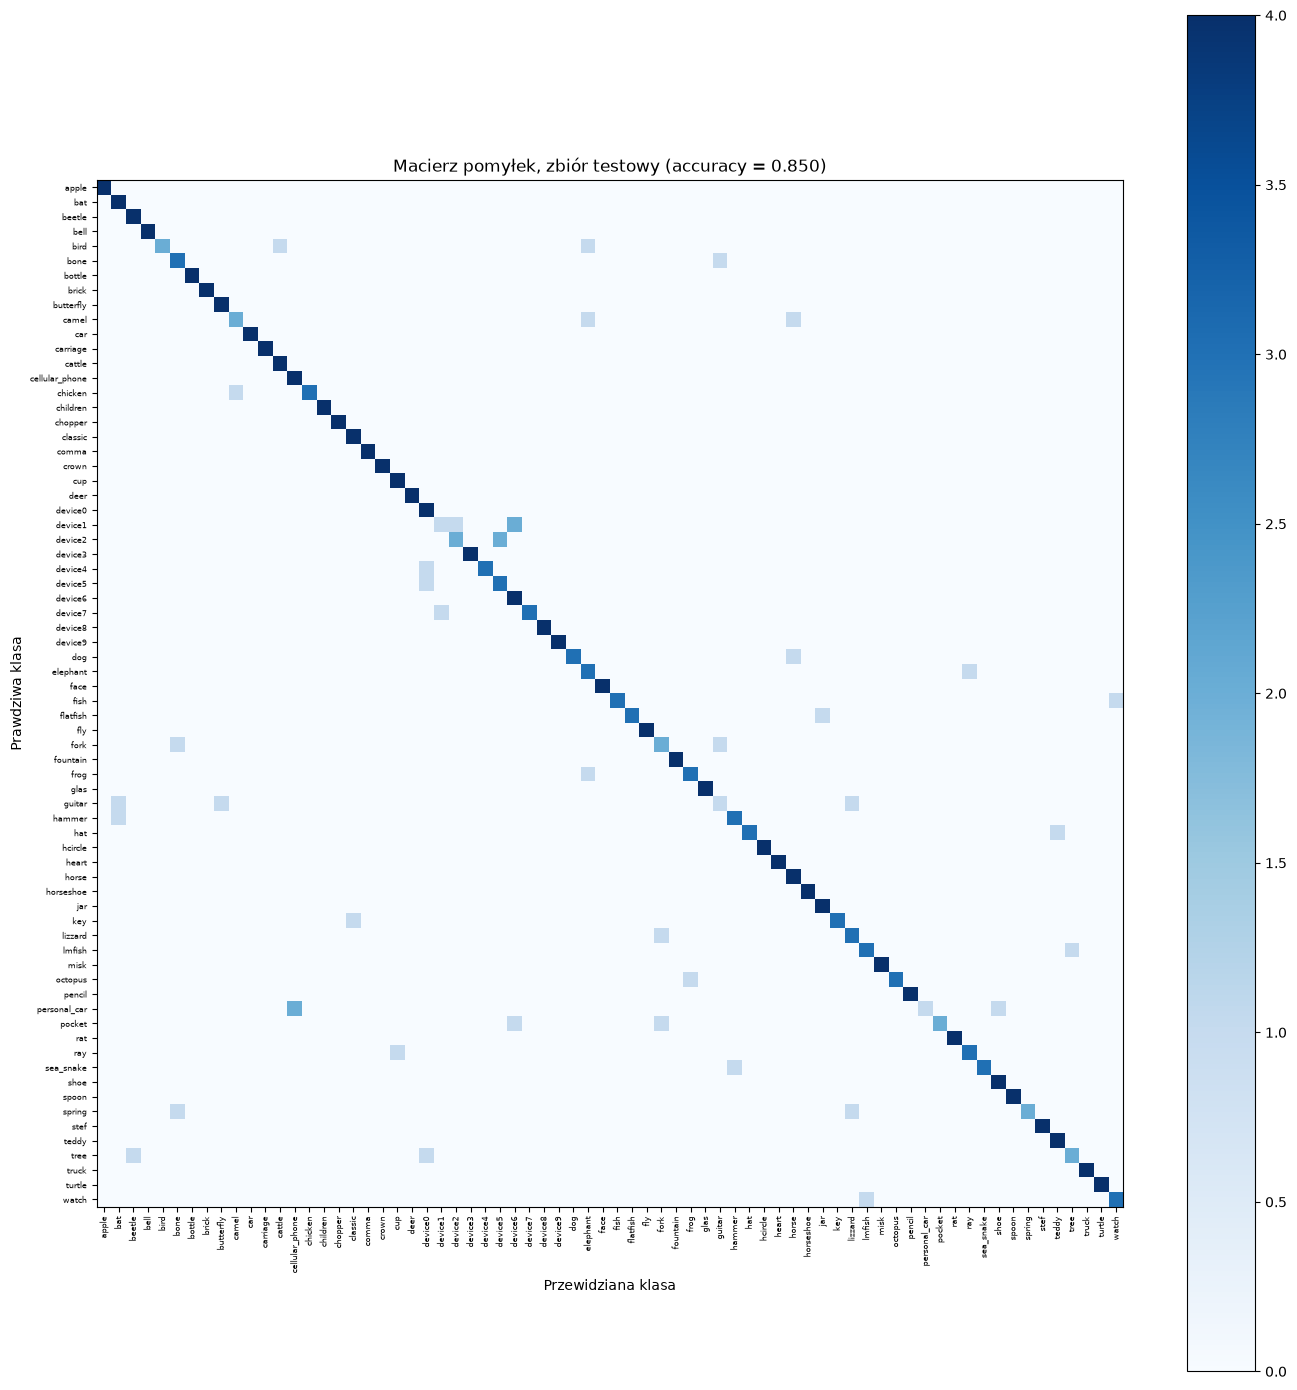

device2 → device5                2
device1 → device6                2
personal_car → cellular_phone    2
watch → lmfish                   1
lizzard → fork                   1
chicken → camel                  1
guitar → bat                     1
bird → cattle                    1
fork → guitar                    1
bone → guitar                    1
Name: count, dtype: int64


In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(14, 14))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, ax=ax, cmap="Blues", include_values=False, xticks_rotation="vertical"
)
ax.tick_params(labelsize=6)
ax.set_xlabel("Przewidziana klasa")
ax.set_ylabel("Prawdziwa klasa")
ax.set_title(f"Macierz pomyłek, zbiór testowy (accuracy = {accuracy_score(y_test, y_pred):.3f})")
plt.tight_layout()
plt.show()

mistakes = pd.Series([f"{t} → {p}" for t, p in zip(y_test, y_pred) if t != p])
print(mistakes.value_counts().head(10))

## 8. Centrowanie obiektu

In [23]:
def center_object(mask):
    """Kwadratowy kadr ze środkiem ciężkości obiektu w środkowym pikselu."""
    rows, cols = np.nonzero(mask)
    r0, c0 = np.rint([rows.mean(), cols.mean()]).astype(int)    # środek ciężkości
    R = int(np.ceil(np.hypot(rows - r0, cols - c0).max())) + 1  # promień koła z obiektem
    out = np.zeros((2 * R + 1, 2 * R + 1), dtype=bool)
    out[rows - r0 + R, cols - c0 + R] = True
    return out


masks_centered = [center_object(m) for m in masks]

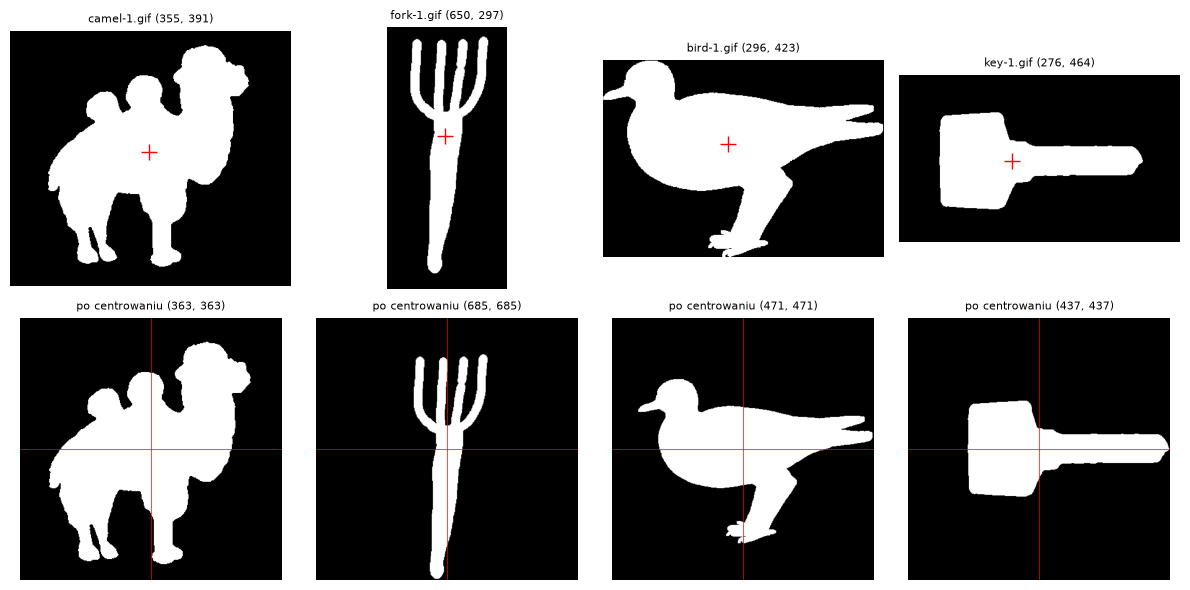

In [24]:
examples = [np.flatnonzero(labels == c)[0] for c in ["camel", "fork", "bird", "key"]]

fig, axes = plt.subplots(2, len(examples), figsize=(3 * len(examples), 6))
for j, i in enumerate(examples):
    rows, cols = np.nonzero(masks[i])
    axes[0, j].imshow(masks[i], cmap="gray")
    axes[0, j].plot(cols.mean(), rows.mean(), "r+", markersize=12)   # x = kolumna, y = wiersz
    axes[0, j].set_title(f"{paths[i].name} {masks[i].shape}", fontsize=8)

    c = masks_centered[i]
    axes[1, j].imshow(c, cmap="gray")
    axes[1, j].axhline(c.shape[0] // 2, color="r", lw=0.5)
    axes[1, j].axvline(c.shape[1] // 2, color="r", lw=0.5)
    axes[1, j].set_title(f"po centrowaniu {c.shape}", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [25]:
rng = np.random.default_rng(0)
sample = rng.choice(len(masks), size=30, replace=False)

before = np.array([simple_features(masks[i]) + complex_features(masks[i]) for i in sample])
after = np.array([simple_features(masks_centered[i]) + complex_features(masks_centered[i]) for i in sample])

print(pd.Series(np.abs(after - before).max(axis=0), index=FEATURE_NAMES))

area              0.000000e+00
perimeter         0.000000e+00
feret_diameter    0.000000e+00
bbox_width        0.000000e+00
bbox_height       0.000000e+00
compactness       0.000000e+00
solidity          0.000000e+00
aspect_ratio      0.000000e+00
ellipticity       0.000000e+00
r_min_max         2.775558e-16
circ_variance     1.110223e-16
asym_best         0.000000e+00
asym_worst        0.000000e+00
dtype: float64


## 9. Normalizacja rozmiaru i porównanie

In [26]:
import time
from skimage.transform import resize

R_TARGET = 128
N = 2 * R_TARGET + 1                     # 257 x 257


def normalize_size(mask):
    """Skaluje wycentrowany kwadratowy kadr do N x N pikseli."""
    scaled = resize(mask.astype(float), (N, N), order=1, anti_aliasing=True)
    return scaled > 0.5


sizes = np.array([m.shape[0] for m in masks_centered])
print("Bok kadru przed skalowaniem: min", sizes.min(), "| mediana", int(np.median(sizes)), "| max", sizes.max())
print("Obrazów zmniejszanych:", (sizes > N).sum(), "| powiększanych:", (sizes < N).sum())

t0 = time.time()
masks_resized = [normalize_size(m) for m in masks_centered]

n_comp_resized = np.array([label(m, connectivity=2).max() for m in masks_resized])
print("Masek rozbitych na kilka części:", (n_comp_resized > 1).sum())
print(Counter(labels[n_comp_resized > 1].tolist()))
masks_resized = [largest_component(m) for m in masks_resized]
print(f"czas: {time.time() - t0:.0f} s")

Bok kadru przed skalowaniem: min 61 | mediana 383 | max 1189
Obrazów zmniejszanych: 1025 | powiększanych: 373
Masek rozbitych na kilka części: 14
Counter({'device1': 4, 'cattle': 2, 'device4': 2, 'misk': 1, 'butterfly': 1, 'device0': 1, 'device2': 1, 'device5': 1, 'fish': 1})
czas: 2 s


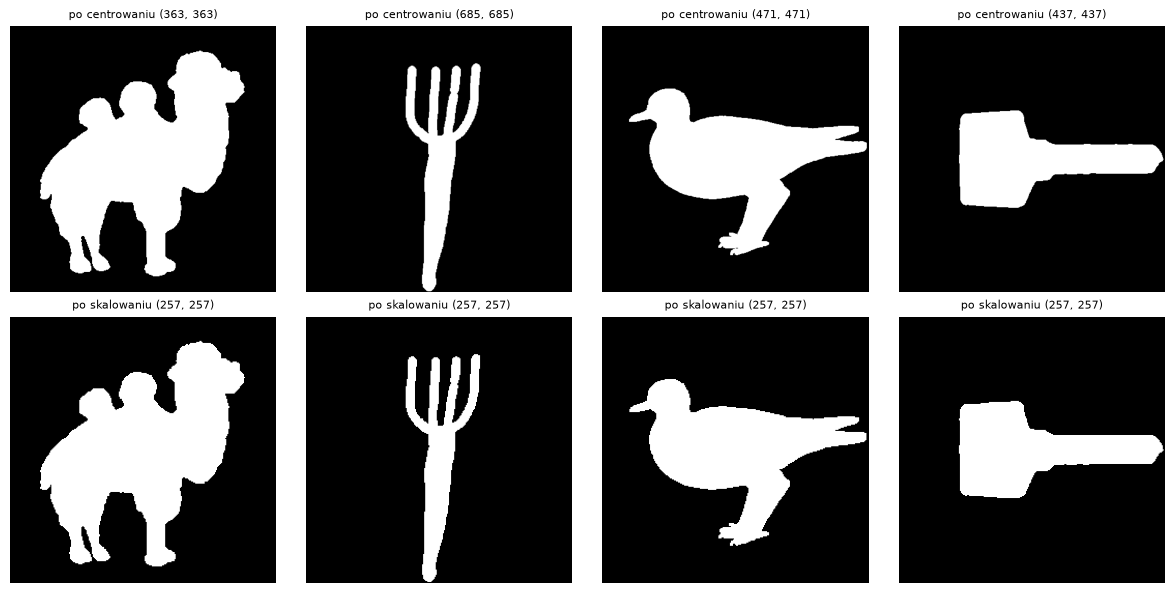

In [27]:
fig, axes = plt.subplots(2, len(examples), figsize=(3 * len(examples), 6))
for j, i in enumerate(examples):
    axes[0, j].imshow(masks_centered[i], cmap="gray")
    axes[0, j].set_title(f"po centrowaniu {masks_centered[i].shape}", fontsize=8)
    axes[1, j].imshow(masks_resized[i], cmap="gray")
    axes[1, j].set_title(f"po skalowaniu {masks_resized[i].shape}", fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [28]:
def all_features(mask_list):
    """Wszystkie 13 cech dla listy masek, w kolejności FEATURE_NAMES."""
    X = np.array([simple_features(m) + complex_features(m) for m in mask_list])
    return pd.DataFrame(X, columns=FEATURE_NAMES)


t0 = time.time()
df_resized = all_features(masks_resized)
df_resized.to_csv("features_resized.csv", index=False)
print(f"czas: {time.time() - t0:.0f} s")
df_resized.describe().round(2)

czas: 11 s


,area,perimeter,feret_diameter,bbox_width,bbox_height,compactness,solidity,aspect_ratio,ellipticity,r_min_max,circ_variance,asym_best,asym_worst
count,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00,1400.00
mean,17691.55,1020.29,235.63,199.40,178.39,0.30,0.72,0.59,0.63,0.27,0.32,0.29,0.44
std,8445.90,497.27,14.08,45.98,53.87,0.19,0.17,0.25,0.25,0.17,0.11,0.19,0.21
min,2371.00,484.07,186.45,42.00,19.00,0.01,0.20,0.06,0.02,0.00,0.01,0.00,0.00
25%,11373.00,668.92,226.00,176.00,137.75,0.14,0.58,0.39,0.44,0.14,0.24,0.15,0.29
50%,16265.00,844.69,238.47,209.00,193.00,0.26,0.76,0.57,0.69,0.26,0.32,0.27,0.41
75%,22656.00,1220.74,246.45,237.00,221.00,0.44,0.85,0.80,0.84,0.37,0.39,0.40,0.60
max,49801.00,3959.23,255.78,255.00,255.00,0.89,1.00,1.00,1.00,0.97,0.59,0.87,0.93


In [29]:
def evaluate(df, cols, scaler=BEST_SCALER):
    """Dobiera k na walidacji, zwraca k oraz accuracy na walidacji i teście."""
    val_scores = []
    for k in ks:
        model = make_pipeline(scaler(), KNeighborsClassifier(n_neighbors=k))
        model.fit(df.loc[idx_train, cols], y_train)
        val_scores.append(model.score(df.loc[idx_val, cols], y_val))
    best_k = ks[int(np.argmax(val_scores))]
    model = make_pipeline(scaler(), KNeighborsClassifier(n_neighbors=best_k))
    model.fit(df.loc[idx_train, cols], y_train)
    return best_k, max(val_scores), model.score(df.loc[idx_test, cols], y_test)


df_variants = {
    "oryginał": df_all,
    "centrowanie": df_all,                       # te same cechy
    "centrowanie + skalowanie": df_resized,
}
feature_sets = {
    "proste (5)": SIMPLE_NAMES,
    "wybrane": selected,
    "wszystkie (13)": FEATURE_NAMES,
}

rows = []
for v_name, df in df_variants.items():
    for f_name, cols in feature_sets.items():
        k, val_acc, test_acc = evaluate(df, cols)
        rows.append({"wariant": v_name, "cechy": f_name, "k": k, 
                     "val": val_acc, "test": test_acc})

comparison = pd.DataFrame(rows)
comparison.round(3)

,wariant,cechy,k,val,test
0,oryginał,proste (5),1,0.736,0.693
1,oryginał,wybrane,1,0.800,0.825
2,oryginał,wszystkie (13),1,0.846,0.850
3,centrowanie,proste (5),1,0.736,0.693
4,centrowanie,wybrane,1,0.800,0.825
5,centrowanie,wszystkie (13),1,0.846,0.850
6,centrowanie + skalowanie,proste (5),1,0.686,0.714
7,centrowanie + skalowanie,wybrane,1,0.821,0.861
8,centrowanie + skalowanie,wszystkie (13),1,0.846,0.868


## 10. Sygnatura kształtu i deskryptor Fouriera

In [30]:
def shape_signature(mask, n_points=256):
    """Odległości od środka ciężkości do n_points punktów rozłożonych równo wzdłuż konturu."""
    c = outer_contour(mask)                              # (wiersz, kolumna), kontur zamknięty
    rr, cc = np.nonzero(mask)
    r0, c0 = rr.mean(), cc.mean()                        # środek ciężkości

    seg = np.hypot(*np.diff(c, axis=0).T)                # długości kolejnych odcinków konturu
    s = np.concatenate([[0], np.cumsum(seg)])            # droga od początku konturu
    t = np.linspace(0, s[-1], n_points, endpoint=False)  # n_points równych kroków
    row_t = np.interp(t, s, c[:, 0])
    col_t = np.interp(t, s, c[:, 1])
    return np.hypot(row_t - r0, col_t - c0)

In [31]:
def fourier_descriptor(mask, n_harmonics=30, n_points=256):
    """|a_1|/a_0, ..., |a_K|/a_0 z transformaty Fouriera sygnatury."""
    r = shape_signature(mask, n_points)
    a = np.abs(np.fft.fft(r)) / n_points                 # |a_n|, a[0] to średni promień
    return a[1:n_harmonics + 1] / a[0]


r = shape_signature(masks[examples[0]])
a = np.abs(np.fft.fft(r)) / len(r)
print("z widma:   ", np.sqrt((a[1:] ** 2).sum()) / a[0])
print("std / mean:", r.std() / r.mean())

z widma:    0.27057471139210104
std / mean: 0.27057471139210104


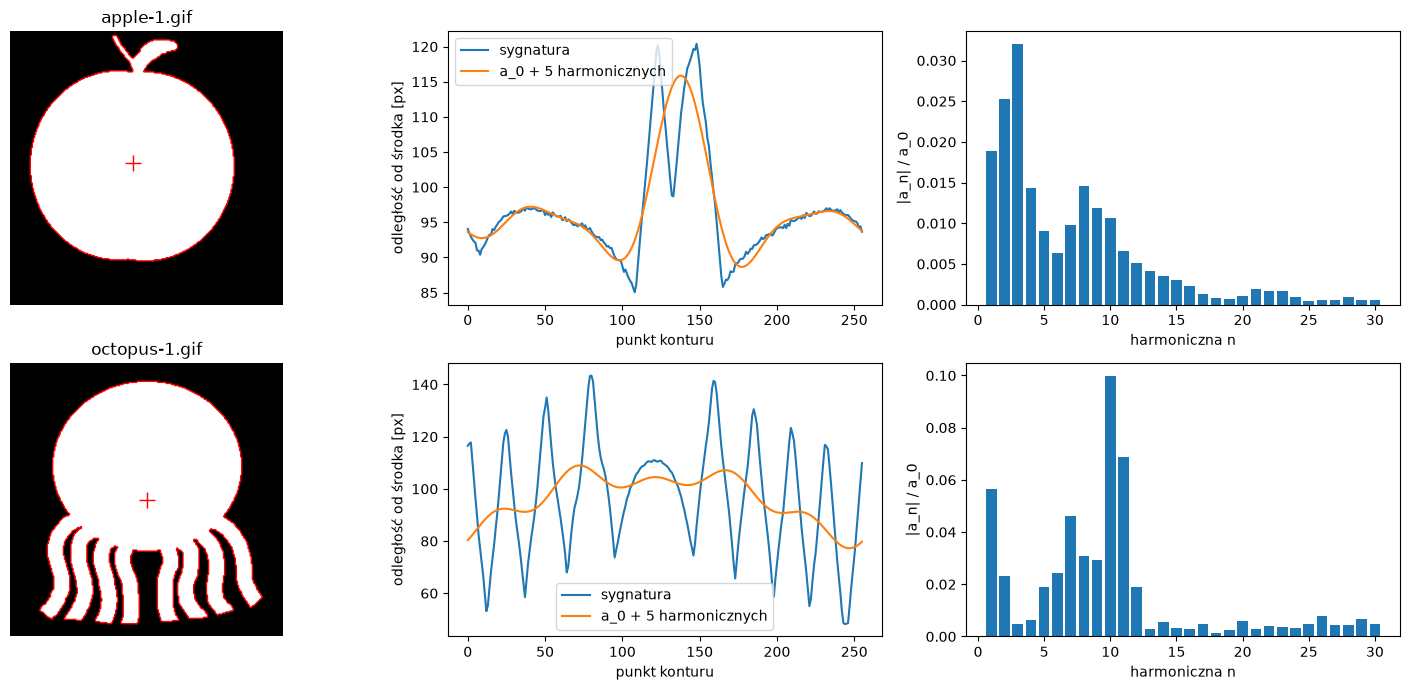

In [32]:
def reconstruct(r, K):
    """Sygnatura odtworzona tylko z a_0 i K pierwszych harmonicznych."""
    A = np.fft.fft(r)
    A[K + 1:len(r) - K] = 0                              # zerujemy wyższe częstotliwości
    return np.fft.ifft(A).real


demo = [np.flatnonzero(labels == c)[0] for c in ["apple", "octopus"]]

fig, axes = plt.subplots(len(demo), 3, figsize=(15, 3.5 * len(demo)))
for ax_row, i in zip(axes, demo):
    m = masks[i]
    c = outer_contour(m)
    rr, cc = np.nonzero(m)
    r = shape_signature(m)
    fd = fourier_descriptor(m)

    ax_row[0].imshow(m, cmap="gray")
    ax_row[0].plot(c[:, 1], c[:, 0], "r", lw=1)                  # x = kolumna, y = wiersz
    ax_row[0].plot(cc.mean(), rr.mean(), "r+", markersize=12)
    ax_row[0].set_title(paths[i].name)
    ax_row[0].axis("off")

    ax_row[1].plot(r, label="sygnatura")
    ax_row[1].plot(reconstruct(r, 5), label="a_0 + 5 harmonicznych")
    ax_row[1].set_xlabel("punkt konturu")
    ax_row[1].set_ylabel("odległość od środka [px]")
    ax_row[1].legend()

    ax_row[2].bar(np.arange(1, len(fd) + 1), fd)
    ax_row[2].set_xlabel("harmoniczna n")
    ax_row[2].set_ylabel("|a_n| / a_0")
plt.tight_layout()
plt.show()

In [33]:
m = masks[idx_camel[0]]
fd_variants = {
    "oryginał": m,
    "skala x2": rescale(m.astype(float), 2, order=1) > 0.5,
    "obrót 45°": rotate(m.astype(float), 45, resize=True, order=1) > 0.5,
    "odbicie": np.fliplr(m),
}
fd_demo = pd.DataFrame(
    {name: fourier_descriptor(v)[:8] for name, v in fd_variants.items()},
    index=[f"n={n}" for n in range(1, 9)],
)
print(fd_demo.round(3))

     oryginał  skala x2  obrót 45°  odbicie
n=1     0.038     0.039      0.036    0.038
n=2     0.122     0.124      0.122    0.122
n=3     0.054     0.050      0.055    0.054
n=4     0.090     0.090      0.090    0.090
n=5     0.051     0.053      0.051    0.051
n=6     0.038     0.037      0.039    0.038
n=7     0.050     0.050      0.049    0.049
n=8     0.012     0.015      0.012    0.012


## 11. Klasyfikacja deskryptorem Fouriera

In [34]:
K_MAX = 60
FD_NAMES = [f"fd{n}" for n in range(1, K_MAX + 1)]

t0 = time.time()
df_fd = pd.DataFrame([fourier_descriptor(m, n_harmonics=K_MAX) for m in masks], columns=FD_NAMES)
df_fd.to_csv("features_fd.csv", index=False)
print(f"czas: {time.time() - t0:.0f} s")
print(df_fd.shape)

czas: 5 s
(1400, 60)


In [35]:
from sklearn.preprocessing import FunctionTransformer


SCALERS = {
    "bez skalowania": FunctionTransformer,
    "MinMaxScaler": MinMaxScaler,
    "StandardScaler": StandardScaler,
}
K_VALUES = [5, 10, 15, 20, 30, 45, 60]

rows = []
for n_harm in K_VALUES:
    for s_name, scaler in SCALERS.items():
        k, val_acc, _ = evaluate(df_fd, FD_NAMES[:n_harm], scaler)
        rows.append({"harmoniczne": n_harm, "skaler": s_name, "k": k, "val": val_acc})

fd_results = pd.DataFrame(rows)
print(fd_results.pivot_table(index="harmoniczne", columns="skaler", values="val").round(3))

best_fd = fd_results.loc[fd_results["val"].idxmax()]
print("\nNajlepszy wariant:")
print(best_fd)

skaler       MinMaxScaler  StandardScaler  bez skalowania
harmoniczne                                              
5                   0.757           0.746           0.754
10                  0.857           0.843           0.850
15                  0.861           0.814           0.846
20                  0.829           0.814           0.846
30                  0.818           0.775           0.850
45                  0.764           0.736           0.850
60                  0.754           0.707           0.850

Najlepszy wariant:
harmoniczne              15
skaler         MinMaxScaler
k                         1
val                0.860714
Name: 7, dtype: object


In [36]:
FD_K = 15                          # liczba harmonicznych wybrana na walidacji
FD_SCALER = MinMaxScaler           # skaler wybrany na walidacji
FD_COLS = FD_NAMES[:FD_K]

k, val_acc, test_acc = evaluate(df_fd, FD_COLS, FD_SCALER)
print(f"Deskryptor Fouriera, {FD_K} harmonicznych, k = {k}: val {val_acc:.3f}, test {test_acc:.3f}")

Deskryptor Fouriera, 15 harmonicznych, k = 1: val 0.861, test 0.875


## 12. Porównanie wyników

In [37]:
t0 = time.time()
df_fd_resized = pd.DataFrame(
    [fourier_descriptor(m, n_harmonics=K_MAX) for m in masks_resized], columns=FD_NAMES
)
df_fd_resized.to_csv("features_fd_resized.csv", index=False)
print(f"czas: {time.time() - t0:.0f} s")

czas: 3 s


In [38]:
W_VALUES = [0.5, 1, 2, 4, 8]


def combine(df_classic, df_fourier, classic_cols, w):
    """Cechy klasyczne i deskryptor Fouriera, każda grupa znormalizowana po swojemu."""
    sc = BEST_SCALER().fit(df_classic.loc[idx_train, classic_cols])
    sf = FD_SCALER().fit(df_fourier.loc[idx_train, FD_COLS])
    classic = pd.DataFrame(sc.transform(df_classic[classic_cols]), columns=classic_cols)
    fourier = pd.DataFrame(w * np.asarray(sf.transform(df_fourier[FD_COLS])), columns=FD_COLS)
    return pd.concat([classic, fourier], axis=1)


def evaluate_combo(df_classic, df_fourier, classic_cols):
    """Dobiera wagę w i k na walidacji, zwraca w, k oraz accuracy na walidacji i teście."""
    best = None
    for w in W_VALUES:
        df = combine(df_classic, df_fourier, classic_cols, w)
        k, val_acc, test_acc = evaluate(df, list(df.columns), FunctionTransformer)
        if best is None or val_acc > best[2]:
            best = (w, k, val_acc, test_acc)
    return best 

In [39]:
prep_variants = {
    "bez preprocessingu": (df_all, df_fd),
    "z preprocessingiem": (df_resized, df_fd_resized),
}

rows = []
for p_name, (df_c, df_f) in prep_variants.items():
    for name, cols in [("proste (5)", SIMPLE_NAMES), ("wybrane", selected),
                       ("wszystkie (13)", FEATURE_NAMES)]:
        k, val_acc, test_acc = evaluate(df_c, cols)
        rows.append({"preprocessing": p_name, "cechy": name, "w": None, "k": k,
                     "val": val_acc, "test": test_acc})

    k, val_acc, test_acc = evaluate(df_f, FD_COLS, FD_SCALER)
    rows.append({"preprocessing": p_name, "cechy": "Fourier", "w": None, "k": k,
                 "val": val_acc, "test": test_acc})

    for name, cols in [("proste + Fourier", SIMPLE_NAMES), ("wybrane + Fourier", selected),
                       ("wszystkie + Fourier", FEATURE_NAMES)]:
        w, k, val_acc, test_acc = evaluate_combo(df_c, df_f, cols)
        rows.append({"preprocessing": p_name, "cechy": name, "w": w, "k": k,
                     "val": val_acc, "test": test_acc})

final = pd.DataFrame(rows)
print(final.round(3))
print()
print(final.pivot_table(index="cechy", columns="preprocessing", values="test", sort=False).round(3))

         preprocessing                cechy    w  k    val   test
0   bez preprocessingu           proste (5)  NaN  1  0.736  0.693
1   bez preprocessingu              wybrane  NaN  1  0.800  0.825
2   bez preprocessingu       wszystkie (13)  NaN  1  0.846  0.850
3   bez preprocessingu              Fourier  NaN  1  0.861  0.875
4   bez preprocessingu     proste + Fourier  1.0  1  0.904  0.918
5   bez preprocessingu    wybrane + Fourier  1.0  1  0.921  0.946
6   bez preprocessingu  wszystkie + Fourier  1.0  1  0.943  0.950
7   z preprocessingiem           proste (5)  NaN  1  0.686  0.714
8   z preprocessingiem              wybrane  NaN  1  0.821  0.861
9   z preprocessingiem       wszystkie (13)  NaN  1  0.846  0.868
10  z preprocessingiem              Fourier  NaN  1  0.854  0.861
11  z preprocessingiem     proste + Fourier  1.0  1  0.886  0.907
12  z preprocessingiem    wybrane + Fourier  2.0  1  0.914  0.932
13  z preprocessingiem  wszystkie + Fourier  1.0  1  0.925  0.939

preproces